# 04 · Exploratory Data Analysis (EDA)

**Dataset:** `data/processed/merged_listings.csv` — Hyderabad property listings merged with locality information.

**Goal:** understand the data and write down the data-quality and modelling issues we find.

**Rules for this notebook** (exploration only):
- the source CSV is only read, never changed or saved
- no outliers removed, no missing values filled, no columns dropped
- no feature engineering, no models

Sometimes we need a number version of a text column just to draw a plot
(for example `bedrooms` is stored as text because of the value `"> 10"`).
Those are temporary variables for plotting only; the `listings` DataFrame itself is never modified.

**Remember:** `price` is the *asking* price in an advert, not a confirmed sale price.

> **Note for the public (GitHub) version of this project**
>
> This notebook needs the original project dataset (`data/processed/merged_listings.csv`), which is **intentionally
> not included** in this repository. It consists of scraped third-party property adverts (with advertiser details),
> and it is excluded for privacy and licensing reasons, and because of its size (about 275 MB). See `data/README.md`.
>
> The **saved outputs below are the record of the analysis** and can be read without the data. The notebook cannot be
> re-run from this repository alone: the next cell checks for the dataset and stops with an explanation if it is missing.

In [ ]:
# Public release: stop with a clear explanation if the (private) dataset is not present.
from pathlib import Path


class DatasetNotIncluded(Exception):
    pass


release_root = Path.cwd()
if not (release_root / "data").is_dir():
    release_root = release_root.parent

if not (release_root / "data" / "processed" / "merged_listings.csv").exists():
    raise DatasetNotIncluded(
        "This notebook needs data/processed/merged_listings.csv from the original project, which is "
        "intentionally not included in the public repository (scraped third-party data). "
        "The saved outputs are the record of the analysis. To re-run it, place the original file at "
        "data/processed/merged_listings.csv (see data/README.md)."
    )

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

# One colour for all single-series charts, a light grid that stays in the background
MAIN_COLOR = "#3366cc"
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e6e6", "axes.edgecolor": "#cccccc"})

# Find the project folder, so the notebook works whether Jupyter starts in the project or in notebooks/
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

MERGED_CSV = PROJECT_ROOT / "data" / "processed" / "merged_listings.csv"

# low_memory=False: read the whole file before guessing column types (avoids mixed-type warnings)
listings = pd.read_csv(MERGED_CSV, low_memory=False)

In [2]:
# Privacy (added before publication): advertiser names and advertiser account IDs are never shown in outputs.
# This only changes what is DISPLAYED. Every calculation in this notebook still uses the original data.
ADVERTISER_NAME_COLUMNS = ["owner_name", "builder_name"]


def hide_advertisers(table):
    shown = table.copy()
    for column in ADVERTISER_NAME_COLUMNS:
        if column in shown.columns:
            # keep missing values missing, hide every actual name
            shown[column] = shown[column].where(shown[column].isna(), "[REDACTED]")
    if "advertiser_id" in shown.columns:
        # Same advertiser -> same label within this table, so "same or different advertiser" stays visible
        labels = {}
        for advertiser in shown["advertiser_id"].dropna():
            if advertiser not in labels:
                labels[advertiser] = f"advertiser {len(labels) + 1}"
        shown["advertiser_id"] = shown["advertiser_id"].map(labels)
    return shown

## 1. Dataset overview

In [3]:
print("Rows:   ", listings.shape[0])
print("Columns:", listings.shape[1])

# deep=True measures the real size of text columns, not just the pointers to them
memory_mb = listings.memory_usage(deep=True).sum() / 1024 ** 2
print(f"Memory usage: {memory_mb:.1f} MB")

Rows:    20694
Columns: 95


Memory usage: 495.4 MB


In [4]:
overview = pd.DataFrame()
overview["dtype"] = listings.dtypes.astype(str)
overview["n_unique"] = listings.nunique()
overview["example_value"] = hide_advertisers(listings.head(1)).iloc[0].astype(str).str[:50]
# Public release: the example listing's advert text, links and raw record are not shown
overview.loc[["description", "raw_json", "detail_url", "image_url", "property_title", "project_name"], "example_value"] = "[not shown]"
overview

,dtype,n_unique,example_value
property_id,int64,20694,listing_001
detail_url,str,20694,[not shown]
locality,str,2542,Patancheruvu
locality_id,float64,2018,106441.0
sub_locality,str,8571,NaN
city,str,1,Hyderabad
latitude,float64,4099,17.513125
longitude,float64,3795,78.259694
coordinates,str,4438,"17.513125,78.259694"
locality_coords,str,2015,"17.513125,78.259694"


Columns starting with `loc_` came from the locality table during the merge (step 02).
`locality_matched` says whether a listing found its locality in that table.

## 2. Missing values

In [5]:
missing = pd.DataFrame()
missing["missing_count"] = listings.isna().sum()
missing["missing_pct"] = (listings.isna().mean() * 100).round(1)
missing = missing.sort_values("missing_pct", ascending=False)
missing

,missing_count,missing_pct
legal_status,20693,100.0
infra_status,20693,100.0
is_rera,20047,96.9
parking,15788,76.3
power_status,15313,74.0
water_status,15231,73.6
flooring_type,13455,65.0
additional_rooms,12088,58.4
luxAmenMap,11918,57.6
lux_amen_desc,11924,57.6


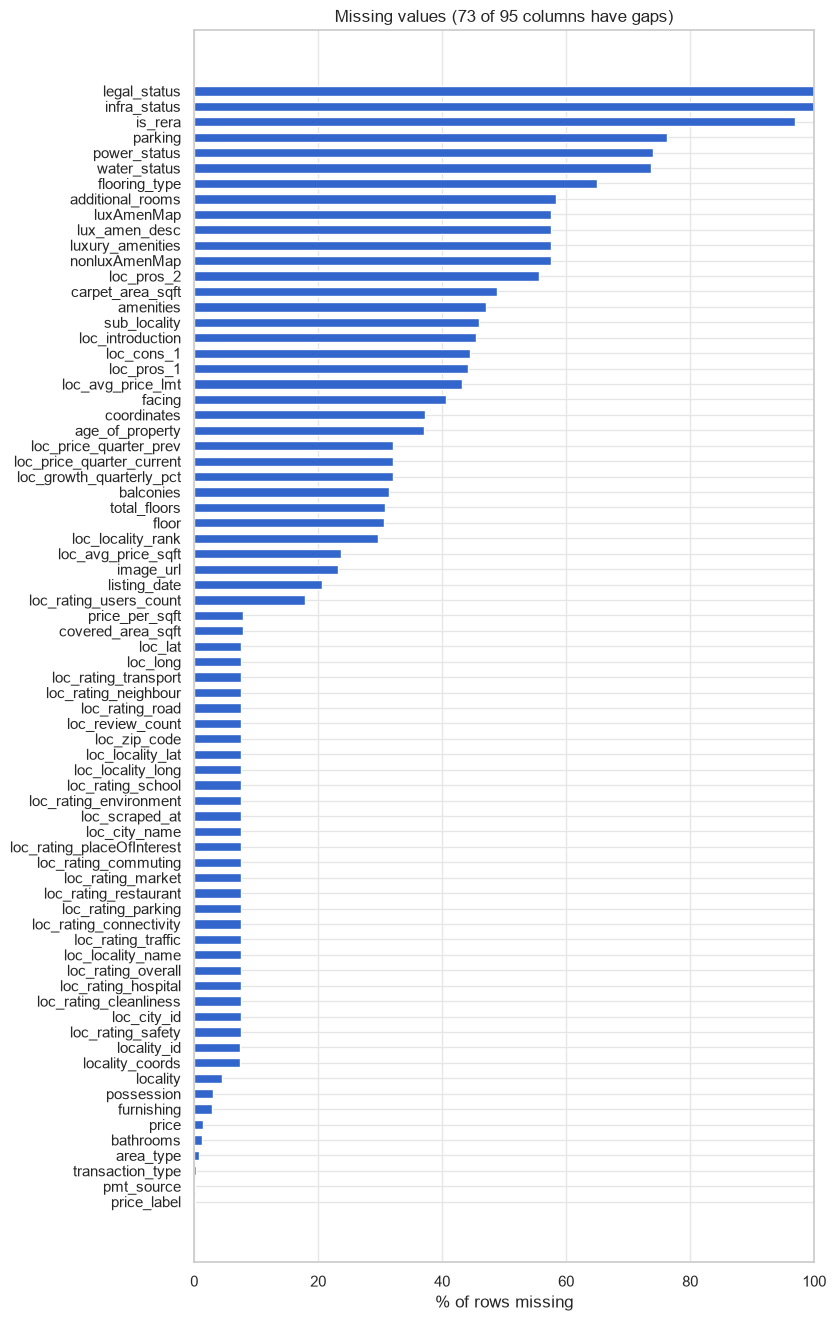

In [6]:
columns_with_missing = missing[missing["missing_count"] > 0]

fig, ax = plt.subplots(figsize=(8, 16))
ax.barh(columns_with_missing.index, columns_with_missing["missing_pct"], color=MAIN_COLOR, height=0.6)
ax.invert_yaxis()
ax.set_xlabel("% of rows missing")
ax.set_title(f"Missing values ({len(columns_with_missing)} of {listings.shape[1]} columns have gaps)")
ax.set_xlim(0, 100)
plt.show()

Some columns look like they go missing *together*.
If that's true, the gaps come from one cause (for example, a failed locality match) rather than random chance.

In [7]:
# All loc_* columns should be empty exactly when the locality did not match
loc_rating = listings["loc_rating_overall"]
print("loc_rating_overall missing:", loc_rating.isna().sum())
print("  ...of which locality not matched:", (loc_rating.isna() & ~listings["locality_matched"]).sum())

# The listing-page "details" fields (power, water, parking...) might all come from the same optional form section
detail_columns = ["power_status", "water_status", "parking", "flooring_type", "additional_rooms"]
all_missing = listings[detail_columns].isna().all(axis=1)
print()
print("Rows missing ALL of", detail_columns, ":", all_missing.sum())

# Pairwise: how often are two columns missing on the same row?
missing_together = listings[detail_columns + ["carpet_area_sqft", "age_of_property", "floor", "facing"]].isna()
missing_together.corr().round(2)

loc_rating_overall missing: 1571
  ...of which locality not matched: 1571

Rows missing ALL of ['power_status', 'water_status', 'parking', 'flooring_type', 'additional_rooms'] : 9509


,power_status,water_status,parking,flooring_type,additional_rooms,carpet_area_sqft,age_of_property,floor,facing
power_status,1.00,0.98,0.76,0.69,0.34,0.21,0.15,0.06,0.39
water_status,0.98,1.00,0.77,0.69,0.35,0.21,0.14,0.06,0.39
parking,0.76,0.77,1.00,0.61,0.33,0.12,0.10,0.04,0.35
flooring_type,0.69,0.69,0.61,1.00,0.46,0.28,0.26,0.14,0.56
additional_rooms,0.34,0.35,0.33,0.46,1.00,0.32,0.30,0.03,0.62
carpet_area_sqft,0.21,0.21,0.12,0.28,0.32,1.00,0.42,0.03,0.36
age_of_property,0.15,0.14,0.10,0.26,0.30,0.42,1.00,0.07,0.41
floor,0.06,0.06,0.04,0.14,0.03,0.03,0.07,1.00,0.15
facing,0.39,0.39,0.35,0.56,0.62,0.36,0.41,0.15,1.00


## 3. Duplicates

Three levels:
1. **Exact duplicate rows**: every column identical.
2. **Duplicate listing IDs**: the same `property_id` twice.
3. **Potential duplicate properties**: different listings describing what looks like the same property.
   We compare the columns that describe the *property itself* (location, price, size, rooms, floor).

In [8]:
print("Exact duplicate rows:    ", listings.duplicated().sum())
print("Duplicate property_id:   ", listings["property_id"].duplicated().sum())

property_columns = ["locality", "price", "covered_area_sqft", "bedrooms", "property_type", "bathrooms", "floor"]
# keep=False marks every member of a duplicate group, not only the second copy
in_duplicate_group = listings.duplicated(subset=property_columns, keep=False)

print("Rows that belong to a potential-duplicate group:", in_duplicate_group.sum())
print("Extra copies (rows beyond the first in each group):", listings.duplicated(subset=property_columns).sum())

Exact duplicate rows:     0
Duplicate property_id:    0
Rows that belong to a potential-duplicate group: 568
Extra copies (rows beyond the first in each group): 306


Not every match is a true duplicate. In a large apartment project, two *different* flats
can have the same size, price and floor number in different towers.
A useful clue: was the group posted by the **same owner**, or by different people?

In [9]:
duplicate_rows = listings[in_duplicate_group]
groups = duplicate_rows.groupby(property_columns, dropna=False)

group_summary = pd.DataFrame()
group_summary["n_listings"] = groups.size()
group_summary["n_owners"] = groups["owner_name"].nunique()
group_summary["n_descriptions"] = groups["description"].nunique()

print("Number of potential-duplicate groups:", len(group_summary))
print("Groups posted by a single owner:     ", (group_summary["n_owners"] == 1).sum())
print("Groups posted by several owners:     ", (group_summary["n_owners"] > 1).sum())
print()
print("Group sizes:")
print(group_summary["n_listings"].value_counts().sort_index())

Number of potential-duplicate groups: 262
Groups posted by a single owner:      19
Groups posted by several owners:      243

Group sizes:
n_listings
2    242
3     10
4      2
5      4
6      3
8      1
Name: count, dtype: int64


In [10]:
# Look at one real group to see what a "duplicate" actually looks like
first_group_key = group_summary.sort_values("n_listings", ascending=False).index[0]
example_group = groups.get_group(first_group_key)
hide_advertisers(example_group[["property_id", "locality", "price", "covered_area_sqft", "bedrooms", "floor",
               "owner_name", "posted_by", "listing_date", "project_name"]])

,property_id,locality,price,covered_area_sqft,bedrooms,floor,owner_name,posted_by,listing_date,project_name
4842,listing_002,"Tellapur, Outer Ring Road",11100000.0,1116,2,NaN,[REDACTED],Agent,NaN,2BHK Multistorey Apartment for New Property in Prestige ...
4850,listing_003,"Tellapur, Outer Ring Road",11100000.0,1116,2,NaN,[REDACTED],Agent,NaN,2BHK Multistorey Apartment for New Property in Prestige ...
4855,listing_004,"Tellapur, Outer Ring Road",11100000.0,1116,2,NaN,[REDACTED],Agent,NaN,2BHK Multistorey Apartment for New Property in Prestige ...
4859,listing_005,"Tellapur, Outer Ring Road",11100000.0,1116,2,NaN,[REDACTED],Agent,2026-06-25T15:58:40.000+00:00,2BHK Multistorey Apartment for New Property in Prestige ...
4868,listing_006,"Tellapur, Outer Ring Road",11100000.0,1116,2,NaN,[REDACTED],Agent,2026-06-25T15:58:54.000+00:00,2BHK Multistorey Apartment for New Property in Prestige ...
6390,listing_007,"Tellapur, Outer Ring Road",11100000.0,1116,2,NaN,[REDACTED],Agent,2026-06-25T15:58:42.000+00:00,2BHK Multistorey Apartment for New Property in Prestige ...
6391,listing_008,"Tellapur, Outer Ring Road",11100000.0,1116,2,NaN,[REDACTED],Agent,2026-06-28T09:03:34.000+00:00,2BHK Multistorey Apartment for New Property in Prestige ...
6392,listing_009,"Tellapur, Outer Ring Road",11100000.0,1116,2,NaN,[REDACTED],Agent,NaN,2BHK Multistorey Apartment for New Property in Prestige ...


In [11]:
print("Duplicate description text:", listings["description"].duplicated().sum())
print("Duplicate image_url:       ", listings["image_url"].dropna().duplicated().sum(),
      "(project photos are often shared by many flats, so this alone does not mean duplicate)")

Duplicate description text: 15
Duplicate image_url:        517 (project photos are often shared by many flats, so this alone does not mean duplicate)


## 4. Target variable: `price`

`price` is the asking price in rupees. For reading the numbers: 1 Lac = 1,00,000 and 1 Cr = 1,00,00,000.

In [12]:
price = listings["price"]

print("Missing:", price.isna().sum())
print(listings.loc[price.isna(), "price_label"].value_counts(dropna=False))

Missing: 280
price_label
Call for Price    263
NaN                17
Name: count, dtype: int64


In [13]:
price_stats = pd.Series({
    "count": price.count(),
    "min": price.min(),
    "1%": price.quantile(0.01),
    "5%": price.quantile(0.05),
    "25%": price.quantile(0.25),
    "median": price.median(),
    "mean": price.mean(),
    "75%": price.quantile(0.75),
    "95%": price.quantile(0.95),
    "99%": price.quantile(0.99),
    "max": price.max(),
    "std": price.std(),
})
print(price_stats.apply("{:,.0f}".format))
print()
print("Skewness:", round(price.skew(), 1), "(0 = symmetric; above 1 is already strongly skewed)")

count              20,414
min               100,000
1%              2,405,200
5%              4,400,000
25%             9,500,000
median         15,000,000
mean           49,579,328
75%            23,000,000
95%            56,661,853
99%           125,000,000
max       250,000,000,000
std         2,239,207,705
dtype: str

Skewness: 94.2 (0 = symmetric; above 1 is already strongly skewed)


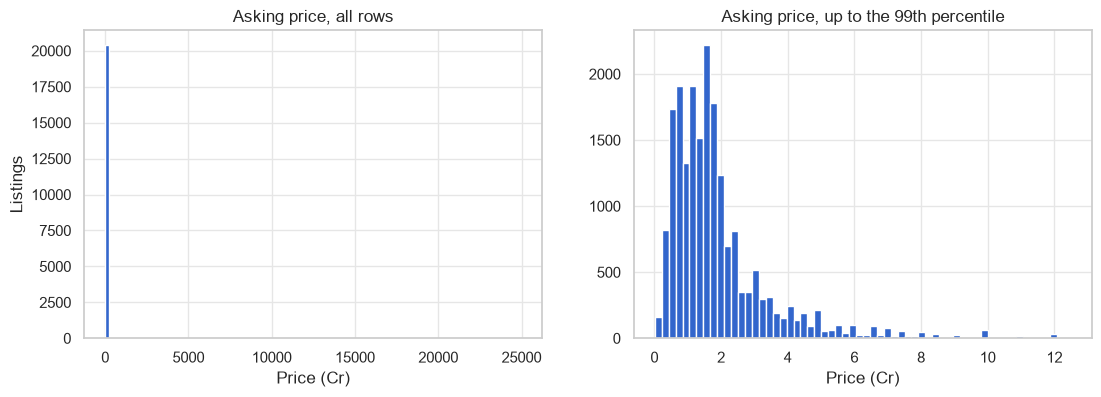

In [14]:
# The raw histogram is almost useless: a few enormous values squash everything else into one bar.
# So we show the raw version next to a view limited to the 99th percentile.
price_99 = price.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(price.dropna() / 1e7, bins=100, color=MAIN_COLOR)
axes[0].set_title("Asking price, all rows")
axes[0].set_xlabel("Price (Cr)")
axes[0].set_ylabel("Listings")

axes[1].hist(price[price <= price_99] / 1e7, bins=60, color=MAIN_COLOR)
axes[1].set_title("Asking price, up to the 99th percentile")
axes[1].set_xlabel("Price (Cr)")
plt.show()

### Would a log transformation help later?

A log turns *multiplying* into *adding*: ₹50 Lac → ₹1 Cr → ₹2 Cr become equally spaced steps.
House prices usually vary in percentages, so on a log scale they often look close to a bell curve.
We only **look** at it here; the target is not transformed.

Skewness of price:        94.22
Skewness of log10(price): 0.41


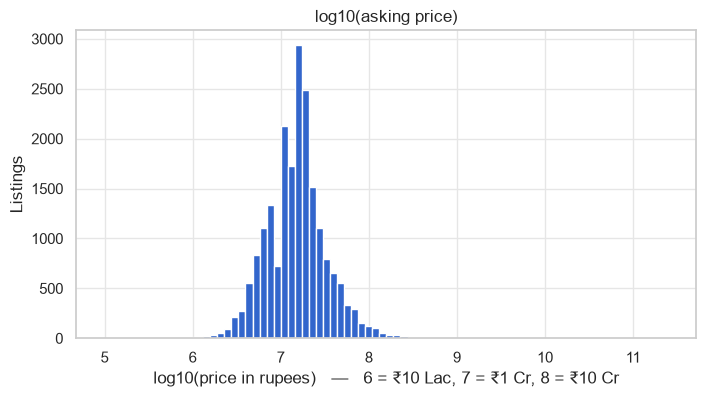

In [15]:
log_price = np.log10(price.dropna())

print("Skewness of price:       ", round(price.skew(), 2))
print("Skewness of log10(price):", round(log_price.skew(), 2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(log_price, bins=80, color=MAIN_COLOR)
ax.set_title("log10(asking price)")
ax.set_xlabel("log10(price in rupees)   —   6 = ₹10 Lac, 7 = ₹1 Cr, 8 = ₹10 Cr")
ax.set_ylabel("Listings")
plt.show()

The most extreme prices, to judge them by eye rather than automatically calling them errors:

In [16]:
look_columns = ["price", "price_label", "property_type", "transaction_type", "bedrooms",
                "covered_area_sqft", "area_type", "locality", "posted_by"]

print("Top 15 prices")
display(listings.nlargest(15, "price")[look_columns])
print("Bottom 15 prices")
display(listings.nsmallest(15, "price")[look_columns])

Top 15 prices


,price,price_label,property_type,transaction_type,bedrooms,covered_area_sqft,area_type,locality,posted_by
19457,2.500000e+11,25000 Cr,Apartment,New Property,4,5000,Sq-ft,Mamidpally,Agent
20641,1.700000e+11,17000 Cr,Residential House,Resale,5,1500,12803,NaN,Owner
19459,1.020800e+11,10208 Cr,Apartment,New Property,4,NaN,Sq-ft,Rajendranagar Mandal,Agent
19727,1.350000e+10,1350 Cr,Apartment,Resale,3,NaN,Sq-ft,Arunodaya Nagar Nagole,Owner
20660,1.216231e+10,1216.23 Cr,Apartment,Resale,2,1233,12800,Power Welfare Society,Owner
19504,1.000109e+10,1000.10 Cr,Apartment,New Property,2,1265,12800,"Hyder Shah Kote, Chevella Road",Agent
19967,8.500000e+09,850 Cr,Apartment,New Property,3,1350,Sq-ft,"Shamshabad, Hyderabad",Owner
20607,6.660000e+09,666 Cr,Apartment,Resale,2,1200,Sq-ft,Shapur Nagar,Owner
20636,2.006000e+09,200.60 Cr,Residential House,Resale,2,150,12803,Suchitra Road,Owner
20663,1.200000e+09,120 Cr,Residential House,Resale,5,4787,12800,"Kokapet, Outer Ring Road",Owner


Bottom 15 prices


,price,price_label,property_type,transaction_type,bedrooms,covered_area_sqft,area_type,locality,posted_by
434,100000.0,1 Lac,Apartment,Resale,2,900,12800,Nacharam,Owner
1312,140000.0,1.4 Lac,Residential House,Resale,2,44,Sq-ft,Picket,Owner
12,142475.0,1.4 Lac,Apartment,New Property,3,1600,Sq-ft,"Moosapet, NH 9",Agent
829,145000.0,1.5 Lac,Residential House,Resale,4,NaN,NaN,Himayatnagar,Owner
1063,190000.0,1.9 Lac,Residential House,Resale,2,NaN,Sq-yrd,"Vanasthalipuram, NH 9",Owner
1429,190000.0,1.9 Lac,Apartment,Resale,1,40,12800,"Nandanavanam Colony, Meerpet",Owner
1430,190000.0,1.9 Lac,Apartment,Resale,1,40,12800,"Nandanavanam Colony, Meerpet",Owner
1264,200000.0,2 Lac,Residential House,Resale,2,60,12800,"Dhatu Nagar, Kanchan Bagh",Owner
1884,272000.0,2.7 Lac,Apartment,Resale,4,3475,12800,"Tellapur, Outer Ring Road",Agent
1553,300000.0,3 Lac,Residential House,Resale,4,585,12803,Kompally,Owner


## 5. Numerical features

Several numeric-looking columns are stored as text:
- `bedrooms`, `bathrooms`, `balconies` contain `"> 10"`
- `floor` contains `"Ground"`, `"Upper Basement"`, `"Lower Basement"`
- `covered_area_sqft` contains values like `"19,000"`

For plotting only, we convert them with `pd.to_numeric(..., errors="coerce")`.
Anything that is not a plain number (like `"> 10"` or `"Ground"`) becomes NaN in these temporary variables.

In [17]:
bedrooms_num = pd.to_numeric(listings["bedrooms"], errors="coerce")
bathrooms_num = pd.to_numeric(listings["bathrooms"], errors="coerce")
floor_num = pd.to_numeric(listings["floor"], errors="coerce")
covered_area_num = pd.to_numeric(listings["covered_area_sqft"].str.replace(",", ""), errors="coerce")

print('bedrooms == "> 10":', (listings["bedrooms"] == "> 10").sum())
print('bathrooms == "> 10":', (listings["bathrooms"] == "> 10").sum())
print("floor values that are not numbers:")
print(listings.loc[floor_num.isna() & listings["floor"].notna(), "floor"].value_counts())

bedrooms == "> 10": 282
bathrooms == "> 10": 235
floor values that are not numbers:
floor
Ground            1725
Upper Basement      67
Lower Basement      64
Name: count, dtype: int64


### Area and its units

The column is called `covered_area_sqft`, but the value is written in whatever unit `area_type` names.
`area_type` mixes readable names with numeric codes. To work out what each code means, we use
the website's own `price_per_sqft` (computed in real square feet):
`price / covered_area / price_per_sqft` should be **1** for sq-ft, **9** for sq-yd and **10.76** for sq-m.

In [18]:
unit_ratio = listings["price"] / covered_area_num / listings["price_per_sqft"]

area_units = pd.DataFrame()
area_units["rows"] = listings["area_type"].value_counts(dropna=False)
area_units["median_area_value"] = covered_area_num.groupby(listings["area_type"]).median()
area_units["median_unit_ratio"] = unit_ratio.groupby(listings["area_type"]).median().round(2)
area_units.sort_values("rows", ascending=False)

,rows,median_area_value,median_unit_ratio
area_type,,,
Sq-ft,9792,1750.0,1.00
12800,8666,1700.0,1.00
12803,1192,177.5,9.00
Sq-yrd,872,230.0,9.00
NaN,137,NaN,NaN
12850,9,1600.0,1.00
Sq-m,9,642.5,9.00
12851,7,120.0,9.00
12801,4,389.5,10.76


Which unit is used for which property type? If houses and villas are mostly measured in square yards,
that is a hint that their "area" is the **plot** (land), while flats report **built-up** area.

In [19]:
pd.crosstab(listings["property_type"], listings["area_type"].fillna("missing"))

area_type,12800,12801,12803,12806,12811,12817,12850,12851,Are,Bigha,Guntha,Sq-ft,Sq-m,Sq-yrd,missing
property_type,,,,,,,,,,,,,,,
Apartment,5570,1,17,1,0,0,3,0,1,0,0,6073,1,16,41
Builder Floor Apartment,501,0,14,0,1,0,0,0,0,0,0,135,0,9,3
Penthouse,26,0,1,0,0,0,1,0,0,0,0,19,0,0,1
Residential House,1715,3,1032,0,0,1,4,6,0,0,0,2075,7,684,70
Villa,854,0,128,0,0,0,1,1,0,1,1,1490,1,163,22


In [20]:
# For a fair look at the distribution, use only rows whose area is already in square feet
is_sqft = listings["area_type"].isin(["Sq-ft", "12800"])
print("Rows with area in square feet:", is_sqft.sum(), "of", len(listings))

print()
print("covered area (sq-ft rows only):")
print(covered_area_num[is_sqft].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(0))
print()
print("carpet_area_sqft:")
print(listings["carpet_area_sqft"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(0))
print()
print("carpet area larger than covered area (normally carpet < built-up):",
      (listings["carpet_area_sqft"] > covered_area_num).sum())

Rows with area in square feet: 18458 of 20694

covered area (sq-ft rows only):
count     17108.0
mean       2193.0
std        6045.0
min           1.0
1%          155.0
5%          800.0
50%        1720.0
95%        5000.0
99%        8000.0
max      560000.0
Name: covered_area_sqft, dtype: float64

carpet_area_sqft:
count    10577.0
mean      1805.0
std       1768.0
min          1.0
1%          92.0
5%         158.0
50%       1450.0
95%       4400.0
99%       7648.0
max      90000.0
Name: carpet_area_sqft, dtype: float64

carpet area larger than covered area (normally carpet < built-up): 467


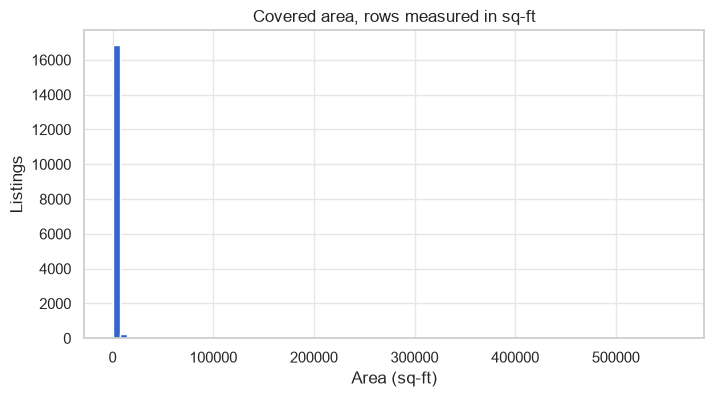

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(covered_area_num[is_sqft], bins=80, color=MAIN_COLOR)
ax.set_title("Covered area, rows measured in sq-ft")
ax.set_xlabel("Area (sq-ft)")
ax.set_ylabel("Listings")
plt.show()

### Rooms and floors

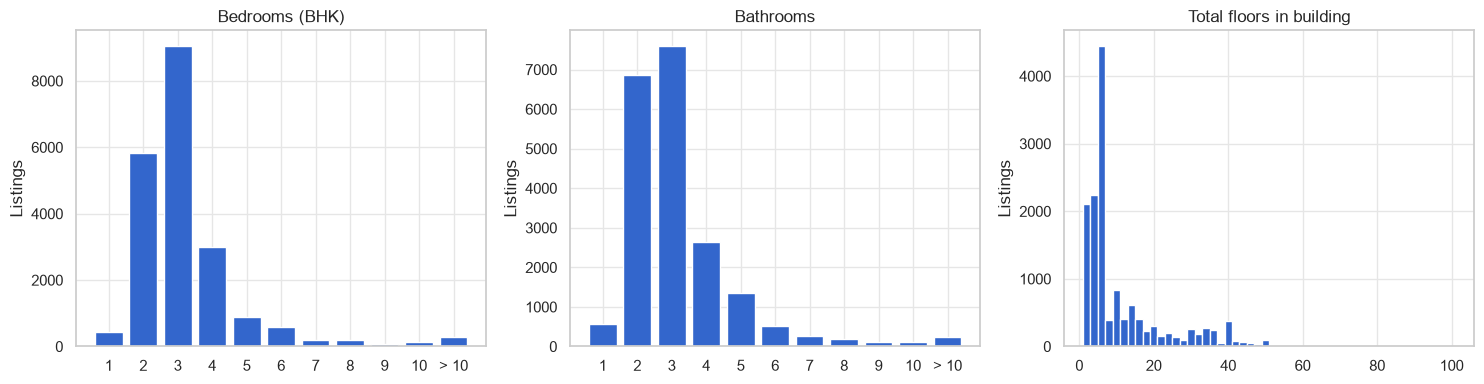

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# value_counts on the original text column keeps "> 10" visible as its own bar
bedroom_order = ["1", "2", "3", "4", "5", "6", "7", "8", "9", "10", "> 10"]
bedroom_counts = listings["bedrooms"].value_counts().reindex(bedroom_order)
axes[0].bar(bedroom_counts.index, bedroom_counts.values, color=MAIN_COLOR)
axes[0].set_title("Bedrooms (BHK)")

bathroom_counts = listings["bathrooms"].value_counts().reindex(bedroom_order)
axes[1].bar(bathroom_counts.index, bathroom_counts.values, color=MAIN_COLOR)
axes[1].set_title("Bathrooms")

axes[2].hist(listings["total_floors"].dropna(), bins=50, color=MAIN_COLOR)
axes[2].set_title("Total floors in building")

for ax in axes:
    ax.set_ylabel("Listings")
plt.tight_layout()
plt.show()

In [23]:
# bhk looks like a code. Compare it with bedrooms to see if it adds anything.
pd.crosstab(listings["bhk"], listings["bedrooms"])

bedrooms,1,10,2,3,4,5,6,7,8,9,> 10
bhk,,,,,,,,,,,
11700,429,0,0,0,0,0,0,0,0,0,0
11701,0,0,5834,0,0,0,0,0,0,0,0
11702,0,0,0,9066,0,0,0,0,0,0,0
11703,0,0,0,0,3010,0,0,0,0,0,0
11704,0,0,0,0,0,876,0,0,0,0,0
11705,0,0,0,0,0,0,584,0,0,0,0
11706,0,0,0,0,0,0,0,203,0,0,0
11707,0,0,0,0,0,0,0,0,199,0,0
11708,0,0,0,0,0,0,0,0,0,88,0


In [24]:
print("Bathrooms more than bedrooms + 3:", (bathrooms_num > bedrooms_num + 3).sum())
print("Floor higher than total floors:  ", (floor_num > listings["total_floors"]).sum())
print("Total floors above 60:           ", (listings["total_floors"] > 60).sum())
print()
print("Floor vs total_floors examples where floor > total_floors:")
listings.loc[floor_num > listings["total_floors"], ["property_type", "floor", "total_floors", "locality"]]

Bathrooms more than bedrooms + 3: 43
Floor higher than total floors:   6
Total floors above 60:            12

Floor vs total_floors examples where floor > total_floors:


,property_type,floor,total_floors,locality
1626,Apartment,7,2.0,Gachibowli
1753,Apartment,4,2.0,"Sanath Nagar, NH 9"
1799,Builder Floor Apartment,3,2.0,NaN
10690,Residential House,3,2.0,Kothapet
16032,Residential House,3,2.0,Bachupally
20383,Residential House,5,4.0,Hitech City Road


### Price-related and locality-level numeric columns

`price_per_sqft` is computed from the target, so it is shown here only to understand it; it can never be a feature.
The `loc_*` price columns (`loc_avg_price_sqft`, `loc_price_quarter_*`, `loc_avg_price_lmt`) may have been
computed from these same listings (see CLAUDE.md, risk 4).

In [25]:
price_like_columns = ["price_per_sqft", "loc_avg_price_sqft", "loc_avg_price_lmt",
                      "loc_price_quarter_current", "loc_price_quarter_prev", "loc_growth_quarterly_pct"]
listings[price_like_columns].describe(percentiles=[0.01, 0.5, 0.99]).T.round(1)

,count,mean,std,min,1%,50%,99%,max
price_per_sqft,19054.0,16016.2,390614.3,0.0,2701.6,8235.0,85000.0,50000000.0
loc_avg_price_sqft,15787.0,7867.4,2752.1,3336.0,3758.2,7002.8,15000.5,23558.4
loc_avg_price_lmt,11761.0,8420.7,1879.1,4930.8,5565.7,7976.9,13795.0,16639.1
loc_price_quarter_current,14045.0,8052.2,3545.5,2140.0,3135.0,7627.0,23058.6,46199.0
loc_price_quarter_prev,14045.0,7949.7,3497.8,2003.0,3098.0,7539.0,22409.0,48692.0
loc_growth_quarterly_pct,14045.0,1.2,3.0,-21.8,-7.7,1.1,11.4,40.6


In [26]:
rating_columns = [column for column in listings.columns if column.startswith("loc_rating_")]
listings[rating_columns + ["loc_review_count", "loc_locality_rank"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
loc_rating_safety,19123.0,3.53,1.63,0.0,3.8,4.1,4.4,5.0
loc_rating_cleanliness,19123.0,3.41,1.59,0.0,3.6,4.0,4.3,5.0
loc_rating_traffic,19123.0,3.15,1.50,0.0,3.3,3.6,4.0,5.0
loc_rating_connectivity,19123.0,3.64,1.68,0.0,3.9,4.3,4.6,5.0
loc_rating_environment,19123.0,3.47,1.60,0.0,3.7,4.0,4.3,5.0
loc_rating_school,19123.0,3.62,1.66,0.0,3.9,4.3,4.5,5.0
loc_rating_hospital,19123.0,3.37,1.65,0.0,3.5,4.0,4.3,5.0
loc_rating_overall,19123.0,3.46,1.58,0.0,3.8,4.0,4.3,5.0
loc_rating_users_count,17015.0,90.06,110.84,1.0,13.0,45.0,144.0,517.0
loc_rating_road,19123.0,3.40,1.58,0.0,3.6,3.9,4.3,5.0


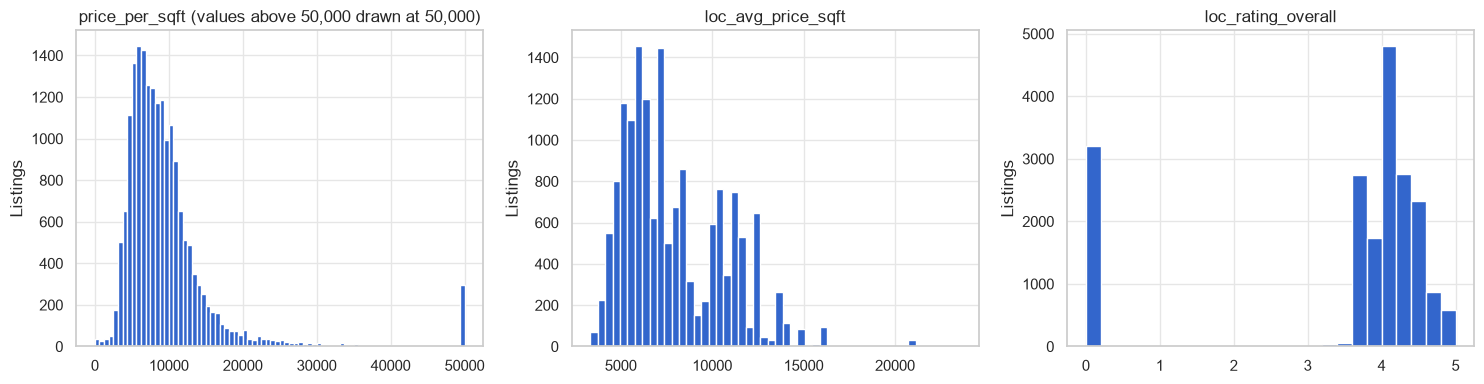

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(listings["price_per_sqft"].clip(upper=50_000).dropna(), bins=80, color=MAIN_COLOR)
axes[0].set_title("price_per_sqft (values above 50,000 drawn at 50,000)")

axes[1].hist(listings["loc_avg_price_sqft"].dropna(), bins=50, color=MAIN_COLOR)
axes[1].set_title("loc_avg_price_sqft")

axes[2].hist(listings["loc_rating_overall"].dropna(), bins=25, color=MAIN_COLOR)
axes[2].set_title("loc_rating_overall")

for ax in axes:
    ax.set_ylabel("Listings")
plt.tight_layout()
plt.show()

## 6. Categorical features

In [28]:
categorical_columns = ["property_type", "transaction_type", "furnishing", "posted_by",
                       "age_of_property", "possession", "facing", "prime_location",
                       "power_status", "water_status", "pmt_source"]

for column in categorical_columns:
    counts = listings[column].value_counts(dropna=False)
    print(f"--- {column}: {listings[column].nunique()} unique values")
    print(counts.head(12).to_string())
    print()

--- property_type: 5 unique values
property_type
Apartment                  11724
Residential House           5597
Villa                       2662
Builder Floor Apartment      663
Penthouse                     48

--- transaction_type: 4 unique values
transaction_type
Resale          17759
New Property     2797
NaN                63
Other              57
Rent               18

--- furnishing: 3 unique values
furnishing
Unfurnished       9988
Semi-Furnished    6299
Furnished         3817
NaN                590

--- posted_by: 3 unique values
posted_by
Owner      18790
Agent       1617
Builder      287

--- age_of_property: 6 unique values
age_of_property
NaN                  7652
New Construction     4508
Less than 5 years    2814
5 to 10 years        2588
10 to 15 years       1554
Above 20 years        815
15 to 20 years        763

--- possession: 51 unique values
possession
Ready to Move         18201
Under Construction     1459
NaN                     611
Dec '26                  5

### Spelling and capitalisation

A simple test: if lower-casing and trimming spaces makes two values the same, they were written inconsistently.

In [29]:
def count_case_variants(column):
    original = listings[column].dropna()
    normalised = original.str.lower().str.strip()
    return original.nunique() - normalised.nunique()


for column in ["locality", "sub_locality", "possession", "facing", "builder_name", "project_name"]:
    print(f"{column:15} unique: {listings[column].nunique():6}   values that differ only by case/spaces: {count_case_variants(column)}")

locality        unique:   2542   values that differ only by case/spaces: 14
sub_locality    unique:   8571   values that differ only by case/spaces: 275
possession      unique:     51   values that differ only by case/spaces: 1
facing          unique:     36   values that differ only by case/spaces: 0
builder_name    unique:  13349   values that differ only by case/spaces: 1359
project_name    unique:  10974   values that differ only by case/spaces: 1


In [30]:
print("possession values containing 'ready':")
print(listings.loc[listings["possession"].str.lower().str.contains("ready", na=False), "possession"].value_counts())
print()
print("facing values that are not compass directions:")
directions = ["East", "West", "North", "South", "North - East", "North - West", "South - East", "South -West"]
print(listings.loc[~listings["facing"].isin(directions) & listings["facing"].notna(), "facing"].value_counts().head(10))

possession values containing 'ready':
possession
Ready to Move    18201
Ready To Move       21
Name: count, dtype: int64

facing values that are not compass directions:
facing
Newly Constructed Property                 238
Near Usha Mullapadi Hospital                 1
Near Income Tax Tower                        1
Near mohammedia masjid                       1
Near TKR Engineering Backside gate.          1
Near Coca Cola company                       1
Near ali forex exchange, new mallepally      1
Near to Yellammabanda Auto Stand             1
Near Nexus Mall and ICON Hospital            1
Near Zia ul haq masjid                       1
Name: count, dtype: int64


### Locality names

`locality` is free text from the listing. `loc_locality_name` is the official name from the locality table.
Comparing them shows the kind of spelling variants we will need to deal with.

In [31]:
matched = listings[listings["locality_matched"]]
name_differs = matched["locality"] != matched["loc_locality_name"]
print("Matched listings whose locality text differs from the official name:", name_differs.sum())

variant_examples = matched.loc[name_differs, ["locality", "loc_locality_name"]].value_counts().head(15)
variant_examples

Matched listings whose locality text differs from the official name: 8862


locality                     loc_locality_name
Narsingi, Outer Ring Road    Narsingi             442
Tellapur, Outer Ring Road    Tellapur             437
Kokapet, Outer Ring Road     Kokapet              394
Miyapur, NH 9                Miyapur              368
Kollur, Outer Ring Road      Kollur               286
Manikonda Jagir              Manikonda            271
Kukatpally, NH 9             Kukatpally           248
Puppalguda                   Puppalaguda          242
Nalagandla                   Nallagandla          228
Patancheruvu                 Patancheru           204
Beeramguda Ramachandrapuram  Beeramguda           176
Uppal, NH 2 2                Uppal                162
Banjara Hills, NH 9          Banjara Hills        153
Boduppal, NH 2 2             Boduppal             124
Pragathi Nagar, Kukatpally   Pragathi Nagar       102
Name: count, dtype: int64

In [32]:
locality_counts = listings["locality"].value_counts()
print("Unique locality strings:", len(locality_counts))
print("Unique locality_id:     ", listings["locality_id"].nunique())
print()
print("Localities with only 1 listing: ", (locality_counts == 1).sum())
print("Localities with fewer than 5:  ", (locality_counts < 5).sum())
print("Localities with 30 or more:    ", (locality_counts >= 30).sum(),
      f"(covering {locality_counts[locality_counts >= 30].sum()} listings)")

Unique locality strings: 2542
Unique locality_id:      2018

Localities with only 1 listing:  1277
Localities with fewer than 5:   1975
Localities with 30 or more:     113 (covering 12111 listings)


## 7. Price relationships

Prices are skewed, so most plots use a **log scale** on the price axis.
Box plots show the median (middle line) and the middle 50% (the box); dots beyond the whiskers are not drawn
so the boxes stay readable.

Correlation is not causation: for example, bathrooms and price move together mainly because
bigger homes have both more bathrooms *and* higher prices.

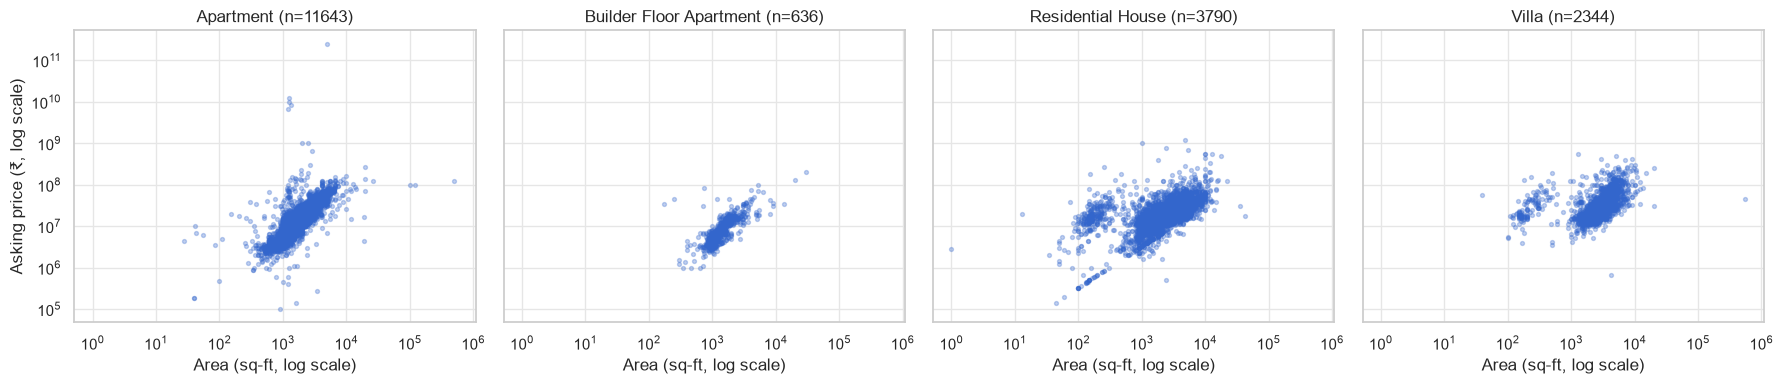

In [33]:
# Area vs price: one small panel per property type, only rows measured in sq-ft,
# because plot area (houses) and built-up area (flats) are not the same thing.
sqft_rows = listings[is_sqft].copy()
sqft_rows["area_value"] = covered_area_num[is_sqft]

property_types = ["Apartment", "Builder Floor Apartment", "Residential House", "Villa"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True, sharey=True)
for ax, property_type in zip(axes, property_types):
    subset = sqft_rows[sqft_rows["property_type"] == property_type]
    ax.scatter(subset["area_value"], subset["price"], s=8, alpha=0.3, color=MAIN_COLOR)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{property_type} (n={len(subset)})")
    ax.set_xlabel("Area (sq-ft, log scale)")
axes[0].set_ylabel("Asking price (₹, log scale)")
plt.tight_layout()
plt.show()

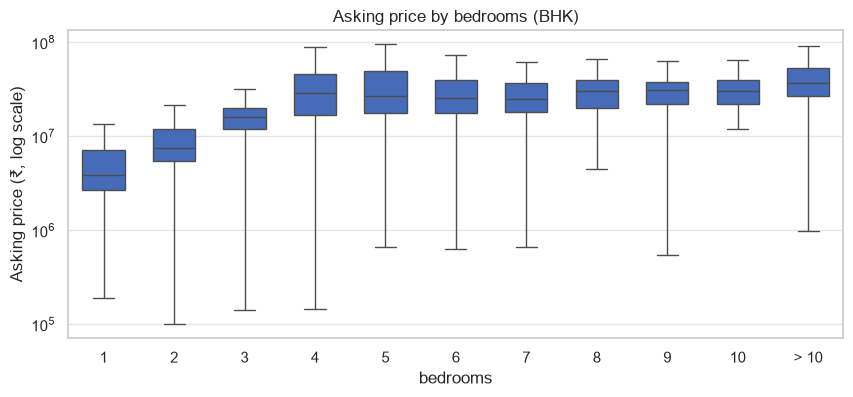

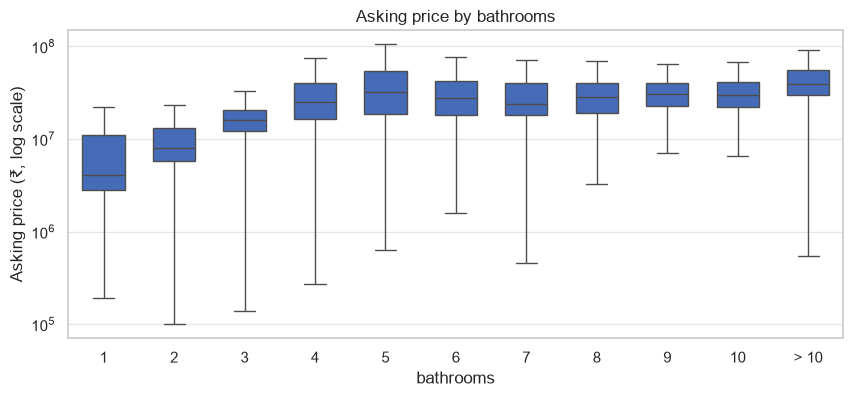

In [34]:
def price_boxplot(column, order=None, title=None, rotate=False):
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.boxplot(data=listings, x=column, y="price", order=order, color=MAIN_COLOR,
                showfliers=False, width=0.6, ax=ax)
    ax.set_yscale("log")
    ax.set_ylabel("Asking price (₹, log scale)")
    ax.set_title(title or f"Asking price by {column}")
    if rotate:
        ax.tick_params(axis="x", rotation=30)
    plt.show()


price_boxplot("bedrooms", order=bedroom_order, title="Asking price by bedrooms (BHK)")
price_boxplot("bathrooms", order=bedroom_order)

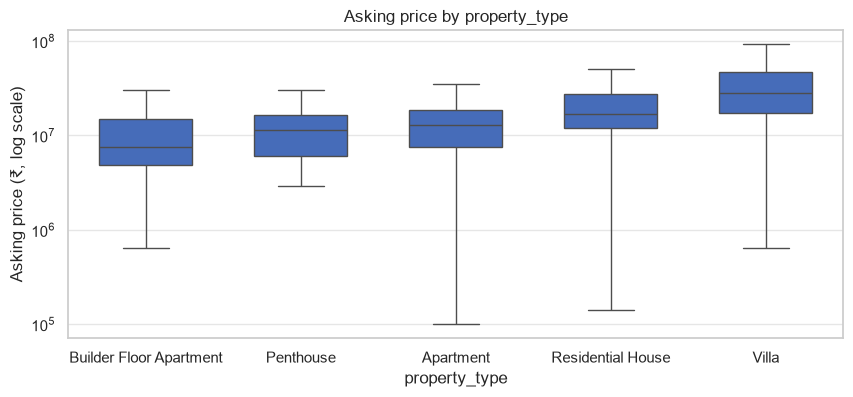

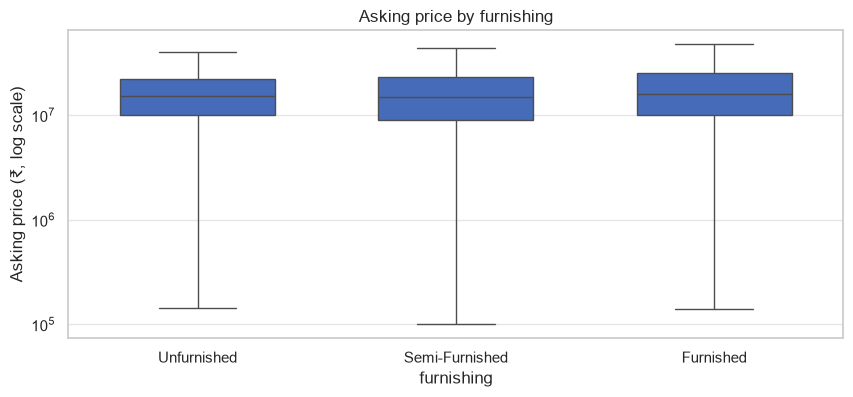

In [35]:
price_boxplot("property_type", order=listings.groupby("property_type")["price"].median().sort_values().index)
price_boxplot("furnishing", order=["Unfurnished", "Semi-Furnished", "Furnished"])

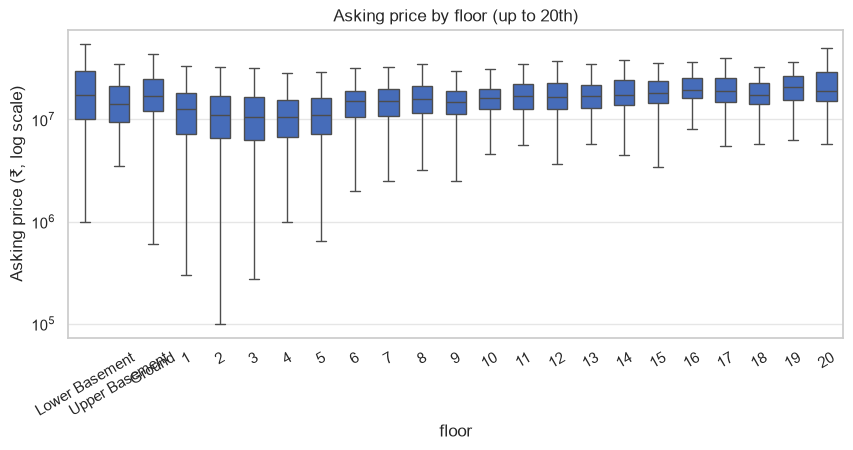

In [36]:
# Floor: show the most common values in a natural order (basements, ground, then numbers)
floor_order = ["Lower Basement", "Upper Basement", "Ground"] + [str(number) for number in range(1, 21)]
price_boxplot("floor", order=floor_order, title="Asking price by floor (up to 20th)", rotate=True)

In [37]:
median_by_type_and_beds = listings.pivot_table(index="bedrooms", columns="property_type",
                                               values="price", aggfunc="median")
(median_by_type_and_beds.reindex(bedroom_order) / 1e5).round(0)

property_type,Apartment,Builder Floor Apartment,Penthouse,Residential House,Villa
bedrooms,,,,,
1,30.0,28.0,42.0,60.0,190.0
2,70.0,52.0,58.0,120.0,160.0
3,155.0,120.0,120.0,160.0,190.0
4,342.0,209.0,120.0,172.0,368.0
5,400.0,150.0,156.0,200.0,447.0
6,410.0,165.0,390.0,240.0,400.0
7,672.0,270.0,NaN,230.0,370.0
8,690.0,190.0,220.0,300.0,374.0
9,190.0,222.0,280.0,310.0,350.0


The table above is in **Lac**. Comparing within a row (same BHK) separates the property-type effect from the BHK effect.

### Spearman correlation with price

Spearman correlation compares **ranks**, not raw values, so a few huge prices do not dominate it
(ordinary Pearson correlation would be pulled around by them).

In [38]:
correlation_inputs = pd.DataFrame({
    "price": listings["price"],
    "area (sq-ft rows only)": covered_area_num.where(is_sqft),
    "carpet_area_sqft": listings["carpet_area_sqft"],
    "bedrooms": bedrooms_num,
    "bathrooms": bathrooms_num,
    "floor": floor_num,
    "total_floors": listings["total_floors"],
    "loc_rating_overall": listings["loc_rating_overall"],
    "loc_locality_rank": listings["loc_locality_rank"],
    "loc_growth_quarterly_pct": listings["loc_growth_quarterly_pct"],
    "loc_avg_price_sqft  (leakage risk)": listings["loc_avg_price_sqft"],
    "loc_price_quarter_current  (leakage risk)": listings["loc_price_quarter_current"],
})

spearman_with_price = correlation_inputs.corr(method="spearman")["price"].drop("price")
spearman_with_price.sort_values(ascending=False).round(2).to_frame("spearman_with_price")

,spearman_with_price
area (sq-ft rows only),0.75
bathrooms,0.64
bedrooms,0.64
carpet_area_sqft,0.57
loc_avg_price_sqft (leakage risk),0.29
loc_price_quarter_current (leakage risk),0.28
floor,0.25
total_floors,0.17
loc_rating_overall,0.10
loc_growth_quarterly_pct,0.07


## 8. Price per square foot

Price per sq-ft is only meaningful when the area measures the same thing.
So we compute it ourselves **only for rows already in sq-ft**, and look at each property type separately
instead of mixing flats (built-up area) with houses (possibly plot area).

In [39]:
sqft_rows["our_price_per_sqft"] = sqft_rows["price"] / sqft_rows["area_value"]

(sqft_rows.groupby("property_type")["our_price_per_sqft"]
          .describe(percentiles=[0.05, 0.5, 0.95])
          .round(0))

,count,mean,std,min,5%,50%,95%,max
property_type,,,,,,,,
Apartment,10754.0,16149.0,503788.0,78.0,4252.0,8000.0,13879.0,50000000.0
Builder Floor Apartment,612.0,6933.0,11941.0,1550.0,2836.0,5544.0,11010.0,204678.0
Penthouse,38.0,8377.0,17130.0,1909.0,3213.0,5142.0,12921.0,110000.0
Residential House,3471.0,18753.0,70278.0,208.0,3296.0,7500.0,84530.0,2800000.0
Villa,2079.0,20512.0,50263.0,80.0,5245.0,10143.0,88273.0,1446000.0


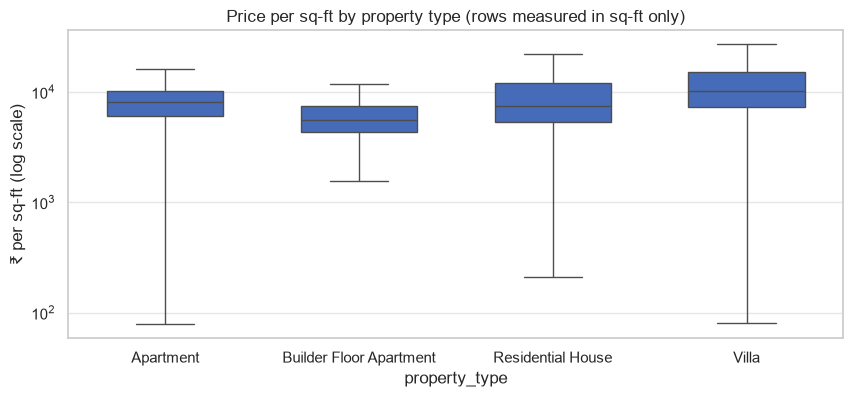

In [40]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=sqft_rows, x="property_type", y="our_price_per_sqft", order=property_types,
            color=MAIN_COLOR, showfliers=False, width=0.6, ax=ax)
ax.set_yscale("log")
ax.set_ylabel("₹ per sq-ft (log scale)")
ax.set_title("Price per sq-ft by property type (rows measured in sq-ft only)")
plt.show()

In [41]:
# Does our own number agree with the website's price_per_sqft on sq-ft rows?
agreement = sqft_rows["our_price_per_sqft"] / sqft_rows["price_per_sqft"]
print("Share of sq-ft rows where ours matches the website's within 1%:",
      round(((agreement - 1).abs() < 0.01).mean(), 3))
print()
print("Very low or very high price per sq-ft (sq-ft rows):")
print("  below ₹1,000:  ", (sqft_rows["our_price_per_sqft"] < 1_000).sum())
print("  above ₹50,000: ", (sqft_rows["our_price_per_sqft"] > 50_000).sum())

Share of sq-ft rows where ours matches the website's within 1%: 0.905

Very low or very high price per sq-ft (sq-ft rows):
  below ₹1,000:   21
  above ₹50,000:  430


## 9. Locality analysis

Descriptive only. Locality-level price statistics computed here must **not** be reused as model features;
if we ever use them, they must be recomputed from the training set only (CLAUDE.md, risk 4).

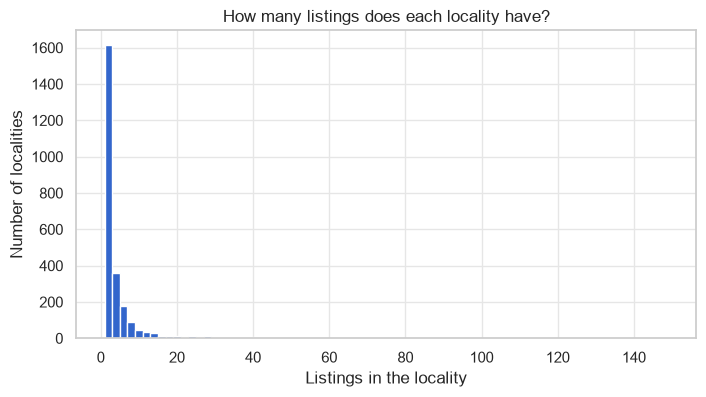

Top 20 localities by listing count:


locality
Kondapur                       583
Bachupally                     450
Narsingi, Outer Ring Road      442
Tellapur, Outer Ring Road      437
Kompally                       397
Kokapet, Outer Ring Road       394
Gachibowli                     369
Miyapur, NH 9                  368
Kollur, Outer Ring Road        286
Manikonda Jagir                271
Kukatpally, NH 9               248
Puppalguda                     242
Nalagandla                     228
Patancheruvu                   205
Hitech City                    202
Nizampet                       184
Sainikpuri                     179
Beeramguda Ramachandrapuram    177
Uppal, NH 2 2                  162
Ameenpur                       156
Name: count, dtype: int64

In [42]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(locality_counts, bins=np.arange(1, 150, 2), color=MAIN_COLOR)
ax.set_title("How many listings does each locality have?")
ax.set_xlabel("Listings in the locality")
ax.set_ylabel("Number of localities")
plt.show()

print("Top 20 localities by listing count:")
locality_counts.head(20)

In [43]:
# Median asking price per locality, only for localities with enough listings to be stable
MIN_LISTINGS = 30
popular_localities = locality_counts[locality_counts >= MIN_LISTINGS].index
popular = listings[listings["locality"].isin(popular_localities)]

locality_summary = pd.DataFrame()
locality_summary["listings"] = popular.groupby("locality").size()
locality_summary["median_price_lac"] = (popular.groupby("locality")["price"].median() / 1e5).round(0)

# Price per sq-ft only for apartments in sq-ft, so the comparison is like-for-like
popular_flats = sqft_rows[(sqft_rows["property_type"] == "Apartment") & sqft_rows["locality"].isin(popular_localities)]
locality_summary["apartment_median_price_per_sqft"] = popular_flats.groupby("locality")["our_price_per_sqft"].median().round(0)

locality_summary = locality_summary.sort_values("median_price_lac", ascending=False)
print(f"{len(locality_summary)} localities with at least {MIN_LISTINGS} listings")
locality_summary

113 localities with at least 30 listings


,listings,median_price_lac,apartment_median_price_per_sqft
locality,,,
Jubilee Hills,75,534.0,10606.0
Mokila,133,331.0,6425.0
"Tukkuguda, Srisailam Highway",54,302.0,5058.0
"Somajiguda, NH 9",60,300.0,12452.0
"Financial District, Nanakram Guda",88,252.0,11486.0
Nanakaramguda,79,250.0,11304.0
"Banjara Hills, NH 9",153,244.0,10350.0
Hitech City,202,240.0,11260.0
"Kokapet, Outer Ring Road",394,225.0,10753.0


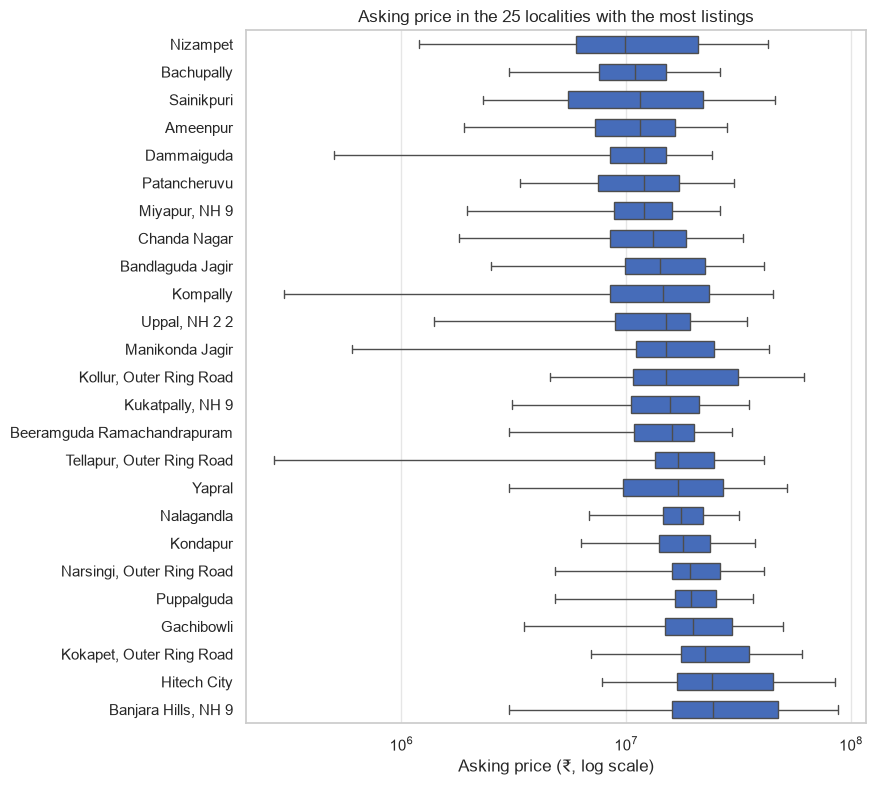

In [44]:
# Price spread in the 25 busiest localities, ordered by median price
busiest = locality_counts.head(25).index
busiest_rows = listings[listings["locality"].isin(busiest)]
order = busiest_rows.groupby("locality")["price"].median().sort_values().index

fig, ax = plt.subplots(figsize=(8, 9))
sns.boxplot(data=busiest_rows, y="locality", x="price", order=order, color=MAIN_COLOR,
            showfliers=False, width=0.6, ax=ax)
ax.set_xscale("log")
ax.set_xlabel("Asking price (₹, log scale)")
ax.set_ylabel("")
ax.set_title("Asking price in the 25 localities with the most listings")
plt.show()

### Listings whose locality did not match the locality table

In [45]:
unmatched = listings[~listings["locality_matched"]]
print("Unmatched listings:", len(unmatched), f"({len(unmatched) / len(listings):.1%})")
print("  of which locality text is empty:", unmatched["locality"].isna().sum())
print("  of which locality_id is empty:  ", unmatched["locality_id"].isna().sum())
print("  of which latitude == 0:         ", (unmatched["latitude"] == 0).sum())
print()
print("Most common locality text among unmatched listings:")
print(unmatched["locality"].value_counts().head(15))

Unmatched listings: 1571 (7.6%)
  of which locality text is empty: 934
  of which locality_id is empty:   1530
  of which latitude == 0:          1490

Most common locality text among unmatched listings:
locality
Hyderabad                   20
Mallapur                    16
Bandlaguda                  12
Hyderabad-West               5
Bacharam                     2
Bachupally                   2
Bahadurpally                 2
Hyderabad-North              2
Miyapur                      2
vanasthalipuram              2
kokapet                      2
patancheru                   2
Manikonda                    2
Ramanthapur                  2
Banjara Hills, Hyderabad     2
Name: count, dtype: int64


In [46]:
# Do unmatched listings look different from matched ones? (If yes, dropping them could bias the data.)
comparison = listings.groupby("locality_matched")["price"].describe(percentiles=[0.25, 0.5, 0.75])
(comparison / 1e5).round(1).assign(count=comparison["count"])

,count,mean,std,min,25%,50%,75%,max
locality_matched,,,,,,,,
False,1535.0,1363.0,43440.2,3.3,70.0,135.0,200.0,1700000.0
True,18879.0,425.3,19717.2,1.0,98.0,152.0,230.0,2500000.0


## 10. Transaction / listing types

In [47]:
print(listings["transaction_type"].value_counts(dropna=False))
print()
(listings.groupby("transaction_type", dropna=False)["price"]
         .describe(percentiles=[0.25, 0.5, 0.75])
         .apply(lambda column: column / 1e5 if column.name != "count" else column)
         .round(1))

transaction_type
Resale          17759
New Property     2797
NaN                63
Other              57
Rent               18
Name: count, dtype: int64



,count,mean,std,min,25%,50%,75%,max
transaction_type,,,,,,,,
New Property,2795.0,1570.0,51125.5,1.4,112.9,167.6,260.0,2500000.0
Other,55.0,219.3,214.2,10.0,105.0,160.0,300.0,1250.0
Rent,15.0,204.1,138.2,40.0,82.5,175.0,300.0,500.0
Resale,17515.0,325.8,12930.8,1.0,90.0,150.0,220.6,1700000.0
NaN,34.0,337.0,461.0,30.0,132.5,190.0,300.8,2500.0


Prices in the table above are in **Lac**. If the `Rent` rows were real rentals, their "price"
would be a monthly rent (thousands of rupees), not lakhs or crores. Let's look at them directly.

In [48]:
rent_or_other = listings[listings["transaction_type"].isin(["Rent", "Other"]) | listings["transaction_type"].isna()]
rent_or_other[["transaction_type", "price_label", "property_type", "bedrooms", "possession",
               "project_name"]].sort_values("transaction_type").head(25)

,transaction_type,price_label,property_type,bedrooms,possession,project_name
844,Other,45 Lac,Apartment,2,Ready to Move,2BHK Multistorey Apartment for Other in RR Enclave at Sh...
11836,Other,1.50 Cr,Villa,3,Ready to Move,3BHK Villa for Other in
12160,Other,1.75 Cr,Villa,5,Ready to Move,5BHK Villa for Other in
20635,Other,12.50 Cr,Apartment,3,Ready to Move,3BHK Multistorey Apartment for Other in
12404,Other,1.50 Cr,Villa,5,Under Construction,"5BHK Villa for Other in Rudraram, NH 9"
12434,Other,1.65 Cr,Apartment,3,Ready to Move,3BHK Multistorey Apartment for Other in
12512,Other,1.55 Cr,Villa,4,Ready to Move,4BHK Villa for Other in
12609,Other,1.60 Cr,Apartment,3,Ready to Move,3BHK Multistorey Apartment for Other in Hitech City
12683,Other,1.50 Cr,Villa,3,Ready to Move,3BHK Villa for Other in
13853,Other,1.98 Cr,Villa,5,Ready to Move,"5BHK Villa for Other in West Venkatapuram, Secunderabad,..."


In [49]:
# The listing title also mentions the transaction ("... for Resale in ..."). Does it agree with transaction_type?
title_says = listings["property_title"].str.extract(r"for (Resale|New Property|Rent|Sale)")[0]
pd.crosstab(listings["transaction_type"].fillna("missing"), title_says.fillna("not in title"))

,New Property,Rent,Resale,not in title
transaction_type,,,,
New Property,2797,0,0,0
Other,0,0,0,57
Rent,0,18,0,0
Resale,0,0,17759,0
missing,0,0,0,63


## 11. Temporal information

Date-like columns:
- `listing_date`: timestamp from the website
- `posted_label`: text shown on the page, like `"Posted: Jun 28, '26"` or `"Posted Yesterday"`
- `scraped_at`: when we downloaded the page (all on one day)
- `possession`: expected possession month for under-construction projects (a future date, not a listing date)

In [50]:
listing_date = pd.to_datetime(listings["listing_date"], utc=True)
scraped_at = pd.to_datetime(listings["scraped_at"]).dt.tz_localize("UTC")

print("listing_date missing:", listing_date.isna().sum())
print("listing_date range:  ", listing_date.min(), "->", listing_date.max())
print("scraped_at range:    ", scraped_at.min(), "->", scraped_at.max())
print("listing_date after scraped_at (impossible):", (listing_date > scraped_at).sum())

listing_date missing: 4256
listing_date range:   2025-07-21 04:42:48+00:00 -> 2026-07-02 04:41:48+00:00
scraped_at range:     2026-07-02 01:38:22+00:00 -> 2026-07-02 10:34:00+00:00
listing_date after scraped_at (impossible): 0


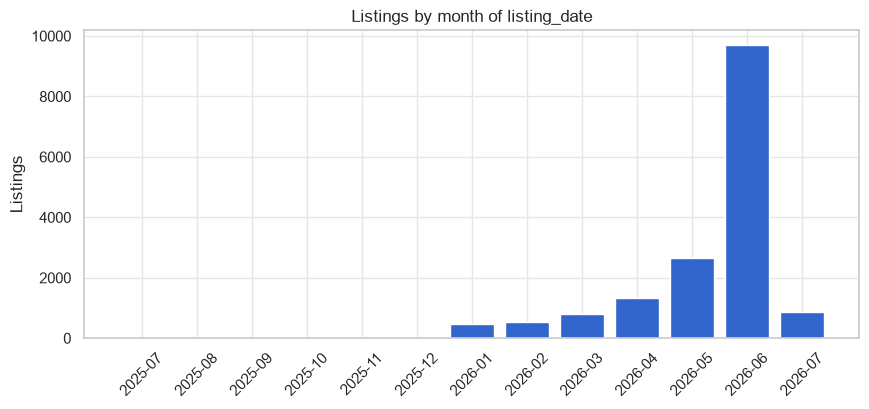

In [51]:
listings_per_month = listing_date.dt.strftime("%Y-%m").value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(listings_per_month.index, listings_per_month.values, color=MAIN_COLOR)
ax.set_title("Listings by month of listing_date")
ax.set_ylabel("Listings")
ax.tick_params(axis="x", rotation=45)
plt.show()

Most listings are from the last month or two before the scrape. That is what a **snapshot** looks like:
older adverts were already sold or removed, so we only see the survivors. The chart describes
*when these adverts were posted*, not how the market changed over time.

In [52]:
# Does posted_label agree with listing_date?
posted_text = listings["posted_label"].str.extract(r"Posted: (\w+ \d+, '\d+)")[0]
# errors="coerce" turns impossible dates into NaT instead of crashing, so we can count them
posted_date = pd.to_datetime(posted_text, format="%b %d, '%y", errors="coerce").dt.tz_localize("UTC")
print("posted_label dates that do not exist on the calendar:",
      posted_text[posted_date.isna() & posted_text.notna()].tolist())
print("posted_label without a date ('Posted Today' / 'Posted Yesterday'):", posted_text.isna().sum())
print()

days_between = (posted_date - listing_date.dt.normalize()).dt.days
print("Rows with both dates:", days_between.notna().sum())
print("Same day:            ", (days_between == 0).sum())
print("posted_label earlier:", (days_between < 0).sum())
print("posted_label later:  ", (days_between > 0).sum())
print()
print(days_between.describe().round(1))
print()
print("listing_date missing but posted_label has a date:", (listing_date.isna() & posted_date.notna()).sum())

posted_label dates that do not exist on the calendar: ["Jun 31, '26"]
posted_label without a date ('Posted Today' / 'Posted Yesterday'): 1492

Rows with both dates: 15238
Same day:             214
posted_label earlier: 9227
posted_label later:   5797

count    15238.0
mean         0.7
std         67.8
min      -2836.0
25%        -26.0
50%         -4.0
75%         21.0
max        300.0
dtype: float64

listing_date missing but posted_label has a date: 3963


In [53]:
# Monthly median asking price, shown only to check for anything odd. With a snapshot this is NOT a market trend.
listing_month = listing_date.dt.strftime("%Y-%m")
monthly = listings.groupby(listing_month)["price"].agg(["count", "median"])
monthly["median"] = (monthly["median"] / 1e5).round(1)
monthly.rename(columns={"median": "median_price_lac"})

,count,median_price_lac
listing_date,,
2025-07,1,72.0
2025-08,1,156.8
2025-09,1,300.0
2025-10,2,270.0
2025-11,4,157.5
2025-12,53,185.0
2026-01,469,175.0
2026-02,543,175.0
2026-03,776,170.0


## 12. Geographic information

In [54]:
latitude = listings["latitude"]
longitude = listings["longitude"]

is_placeholder = (latitude == 0) & (longitude == 0)
# A generous box around Greater Hyderabad
in_hyderabad_box = latitude.between(16.9, 17.9) & longitude.between(78.0, 79.0)

print("Placeholder coordinates (0, 0):    ", is_placeholder.sum(), f"({is_placeholder.mean():.1%})")
print("Inside the Hyderabad box:          ", in_hyderabad_box.sum())
print("Non-zero but outside the box:      ", (~is_placeholder & ~in_hyderabad_box).sum())
print("Placeholder rows that also have no locality match:", (is_placeholder & ~listings["locality_matched"]).sum())

Placeholder coordinates (0, 0):     7728 (37.3%)
Inside the Hyderabad box:           12842
Non-zero but outside the box:       124
Placeholder rows that also have no locality match: 1490


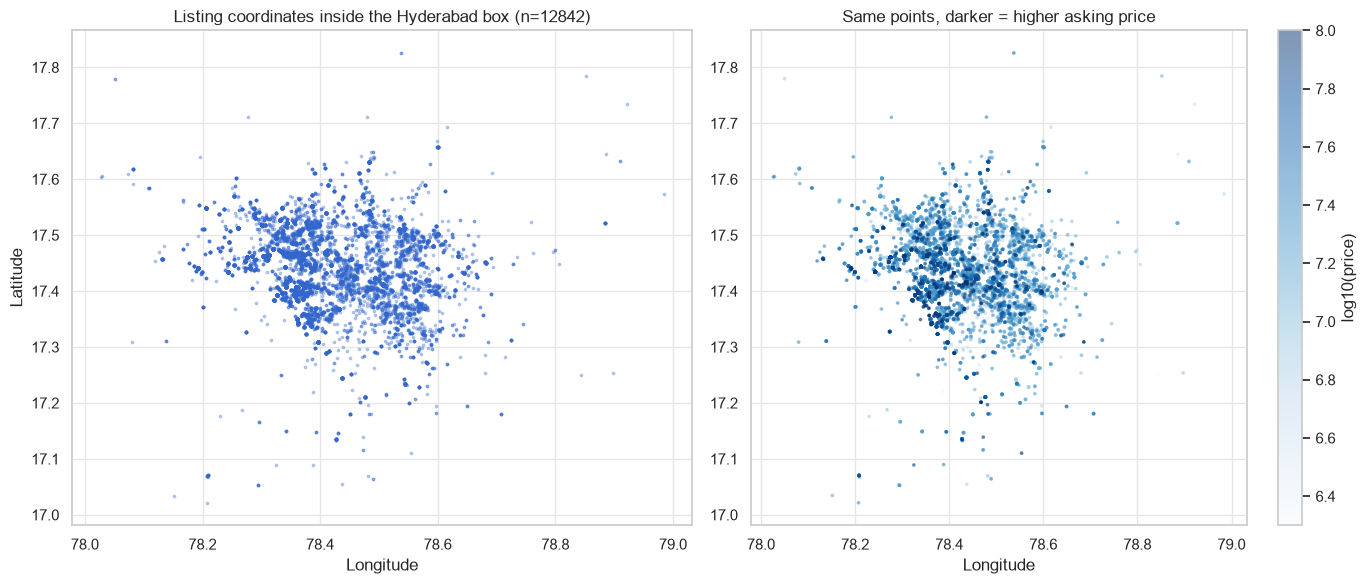

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

valid = listings[in_hyderabad_box]
axes[0].scatter(valid["longitude"], valid["latitude"], s=3, alpha=0.3, color=MAIN_COLOR)
axes[0].set_title(f"Listing coordinates inside the Hyderabad box (n={len(valid)})")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

# Same map coloured by log price, to see whether location is visibly related to price
points = axes[1].scatter(valid["longitude"], valid["latitude"], s=3, alpha=0.5,
                         c=np.log10(valid["price"]), cmap="Blues", vmin=6.3, vmax=8)
axes[1].set_title("Same points, darker = higher asking price")
axes[1].set_xlabel("Longitude")
fig.colorbar(points, ax=axes[1], label="log10(price)")
plt.tight_layout()
plt.show()

In [56]:
outside = listings[~is_placeholder & ~in_hyderabad_box]
outside[["latitude", "longitude", "locality", "loc_lat", "loc_long"]].head(10)

,latitude,longitude,locality,loc_lat,loc_long
126,78.566976,17.238220,Adibatla,17.234375,78.543777
998,18.103476,78.849075,Siddipet,18.103476,78.849075
1020,17.037853,77.764992,"King Koti, Hyderguda",17.393606,78.484253
1043,78.412308,17.324070,Sangareddy,17.619013,78.081337
1073,17.298496,77.983038,Manneguda,17.252121,78.585670
1452,17.927340,78.262436,Pothireddipally,17.927340,78.262436
1959,18.020634,78.068696,Narsinghi,18.020634,78.068695
2010,17.027283,77.788437,Mallikarjuna Nagar Amberpet,17.396521,78.525314
2015,17.027323,77.788437,Nadergul Road,17.282665,78.558708
2018,17.026772,77.790802,"LB Nagar, NH 9",17.358328,78.552544


In [57]:
# How far is each listing from its locality's centre? Large gaps suggest a wrong pin or a wrong locality.
# 1 degree of latitude is about 111 km; this rough conversion is good enough for a sanity check.
both_valid = in_hyderabad_box & listings["loc_lat"].notna()
km_north = (listings["latitude"] - listings["loc_lat"]) * 111
km_east = (listings["longitude"] - listings["loc_long"]) * 111 * np.cos(np.radians(17.4))
distance_km = np.sqrt(km_north ** 2 + km_east ** 2)[both_valid]

print(distance_km.describe(percentiles=[0.5, 0.9, 0.99]).round(1))
print("Listings more than 10 km from their locality centre:", (distance_km > 10).sum())

count    12764.0
mean         2.4
std          6.4
min          0.0
50%          0.4
90%          6.1
99%         25.0
max        108.1
dtype: float64
Listings more than 10 km from their locality centre: 851


## 13. EDA Findings and Questions for Data Cleaning

Nothing below is a final decision. These are observations and open questions for the cleaning stage.
The target is the **asking price** in adverts (about 91% posted by owners), not a confirmed sale price.

### 1. Important patterns

- **Price is extremely right-skewed:** skewness is 94 for raw price and 0.41 for `log10(price)`.
  The median is ₹1.5 Cr and the middle 50% runs from ₹95 Lac to ₹2.3 Cr.
  A log target looks very suitable, but it has not been applied yet.
- **Size drives price the most:** Spearman correlation with price is 0.75 for area (sq-ft rows only),
  0.64 for bedrooms and bathrooms, and 0.57 for carpet area. Bedrooms and bathrooms mostly repeat the size signal.
- **Property type matters even at the same BHK:** a 3 BHK apartment has a median of about ₹1.55 Cr,
  while a 3 BHK villa is about ₹1.9 Cr.
  Apartments with 7 to 10+ BHK have medians of ₹6 to 10 Cr, which looks more like whole buildings than single flats.
- **Location matters:** among localities with 30+ listings, median prices range from about ₹5.3 Cr (Jubilee Hills)
  down to a few tens of lakhs. The price map also shows a clear west-side (Hitech City / Gachibowli) premium.
- **Locality ratings are only weakly related to price** (Spearman 0.10). The locality price columns are more related (0.28–0.29).
- **Monthly median asking price falls from about ₹1.75 Cr (Jan) to ₹1.32 Cr (Jun).**
  This is almost certainly a snapshot effect: June has 9.6k fresh listings, while older months only contain adverts
  that have not sold yet. It is **not** evidence of a market trend.

### 2. Potential data-quality problems

| Area | What we saw |
|---|---|
| Target | 280 rows have no price (263 "Call for Price", 17 blank). 8 listings are above ₹500 Cr (up to ₹25,000 Cr) and 31 are below ₹5 Lac. These need a look, not automatic removal. |
| Area units | `covered_area_sqft` is in the unit named by `area_type`: 12800/Sq-ft = sq-ft, 12803/Sq-yrd = sq-yd, 12801 = sq-m. "Sq-m" and 12851 behave like sq-yd (ratio 9). 137 rows have no unit. 108 values contain commas. |
| Area meaning | Houses and villas use sq-yd much more often (1,716 of 5,597 houses), which suggests plot area. Price per sq-ft for houses and villas has a 95th percentile of about ₹85k, compared with ₹14k for apartments. |
| Area values | Area ranges from 1 to 560,000 on sq-ft rows. 467 rows have carpet area larger than covered area. |
| Area vs price plot | On "sq-ft" rows, houses and villas show a separate cluster at 100–300 area units priced at ₹1–5 Cr. These look like **sq-yd values labelled as sq-ft**. Houses also show a thin straight line of low area and low price, so some prices might be per-unit amounts. |
| Rooms / floors | 43 rows have more than bedrooms + 3 bathrooms. 6 rows have floor above total floors. 12 buildings have more than 60 floors. |
| Transaction type | `Rent` (18) and `Other` (57) rows have **sale-sized prices** (Rent median ₹1.75 Cr), so their label may be wrong. 63 rows have no transaction type. |
| Locality ratings | 3,199 rows have `loc_rating_*` = 0. These localities have almost no reviews, so **0 means "no rating", not "bad"**. |
| Coordinates | 7,728 rows (37%) sit at the placeholder (0, 0). 4 rows have latitude and longitude swapped. 11 rows share one suspicious point (17.03, 77.79). 851 listings are more than 10 km from their locality centre. |
| Dates | `listing_date` is missing for 4,256 rows. `posted_label` usually disagrees with `listing_date` (only 214 same-day matches), so they likely mean different events. One label reads "Jun 31", which doesn't exist. |
| Text categories | "Ready to Move" and "Ready To Move" both appear. `facing` contains landmarks and "Newly Constructed Property". `builder_name` has 1,359 case-only variants. |
| Missing blocks | 9,509 rows are missing all of power, water, parking, flooring and additional rooms together. That looks like an absent section of the listing page, not random gaps. |

### 3. Potential leakage risks

- **Direct copies of the target:** `price_per_sqft`, `price_label`, `raw_json` (contains `price`) and `description` (often states the price).
- **Locality price statistics** (`loc_avg_price_sqft`, `loc_avg_price_lmt`, `loc_price_quarter_*`, `loc_growth_quarterly_pct`)
  may be computed from these same listings. If ever used, they must be rebuilt from training data only.
- **Duplicate groups:** 262 groups with 568 rows share the same locality, price, area, rooms and floor.
  243 of those groups were posted by *different* owners/agents (for example, 8 agents listing the same Prestige unit in Tellapur).
  If one group is split across train and test, the model sees the answer. Deduplicate or group-split before modelling.

### 4. Features that may need transformation (later, not now)

- `price`: log transform.
- `covered_area_sqft`: remove commas, convert to one unit, and possibly treat plot area separately from built-up area.
- `bedrooms`, `bathrooms`, `balconies`: text containing `"> 10"`, so they need converting to numbers.
- `floor`: Ground and basements need numeric codes.
- `possession`: a mix of status and future months.
- `listing_date`: parse it, or leave it out.
- `amenities` / `luxury_amenities`: space-separated codes.
- `locality`: normalise spelling variants such as "Puppalguda"/"Puppalaguda", "Nalagandla"/"Nallagandla" and the ", NH 9" / ", Outer Ring Road" suffixes.
- `loc_rating_*`: 0 should probably become "missing".

### 5. Features that may need to be removed

- **Constant:** `city`, `is_Luxury`, `has_rera`, `detail_scraped`.
- **Almost empty:** `legal_status`, `infra_status`, `is_rera` (97% missing).
- **Duplicates of other columns:** `bhk` (= `bedrooms`), `property_title` (= `project_name`), `loc_locality_lat/long` (= `loc_lat/long`), and `coordinates` / `locality_coords` (repeat lat/long).
- **Identifiers and scraping details:** `property_id`, `detail_url`, `image_url`, `scraped_at`, `loc_scraped_at`, `raw_json`, `pmt_source`.
- **Leakage:** `price_per_sqft`, `price_label`, `description`.

### 6. Questions that must be answered before modelling

1. Which `transaction_type` values count as "for sale"? Are the Rent and Other rows mislabelled sales, or should they be excluded?
2. What rule separates a genuine extreme price from a typing error (for example, comparing price per sq-ft against the property type)?
3. Can every `area_type` code be converted safely? What happens to rows with no unit, or with Bigha/Guntha/Are?
4. Should houses and villas (possibly plot area) be modelled together with flats, or separately, or flagged by area type?
5. For duplicate groups: what counts as the *same property*, and should the split be grouped by project so near-copies never cross train and test?
6. How many unmatched localities can be recovered by normalising names, and how should the rest be handled?
7. Should 0 locality ratings be treated as missing?
8. Is `listing_date` useful as a feature, given it mostly reflects how long an advert has survived?
9. Which coordinates can be trusted (not 0, not swapped, within a reasonable distance of the locality centre)?
10. Does missingness itself carry information? For example, rows missing the whole "details" block may be a different listing flow.